# Model: Avocado price prediction (next week)
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella | **Dataset:** [Avocado Prices (Kaggle, neuromusic)](https://www.kaggle.com/neuromusic/avocado-prices) — Hass Avocado Board data | **Type:** regression (time series)

This notebook follows the project template and leaves the model ready for the API (`models/avocado.joblib` + `predictors/avocado.py`).

Voice command: *"JarvisTEC, price of organic avocados in Boston next week"*

## 1. Problem analysis (0.5 pt)

**What do we want to predict?** The average price of a Hass avocado in the **following week**, for a region of the United States and a type (conventional or organic). It serves to answer commands such as *"JarvisTEC, avocado price for next week"*.

**Why is it hard?** In a price series, the best that is known about next week's price is this week's. That is why, before accepting a model, it has to be compared with the **naive baseline**: *"next week it will cost the same as this week"* (Hyndman and Athanasopoulos, 2021). A model is only useful if it beats it.

**Design decisions**
- **Target variable:** the price *change* from one week to the next, not the price. This way the model has to contribute something more than repeating the current price; the price is rebuilt as `this week's price + predicted change`.
- **Input features:** derived only from the past prices of the series itself (recent changes, distance to its mean over the last month and the last three, and time of year). This way the API can predict with just a list of prices. The volume sold is not used: next week's volume is not known when predicting.
- **A single model for all the series** (regions and types), with about 16,800 rows, instead of one model per series with 169 weeks each.
- **No time shuffling:** it is trained with the past and evaluated with the future.
- **Metrics:** RMSE and MAE in dollars, and R² of the change.
- **Success criterion:** beat the naive baseline.

## 2. Data understanding (0.5 pt)

The data is from the Hass Avocado Board: weekly sales of Hass avocados in United States retailers, from January 2015 to March 2018. Each row is a **week, region and type**: 18,249 rows.

| Column | Meaning |
|---|---|
| `Date` | Date of the week (one record per week) |
| `AveragePrice` | **Basis of the target.** Average price of an avocado that week, in USD |
| `type` | `conventional` or `organic` |
| `region` | 54 regions: cities, larger areas (for example `West`) and the whole country (`TotalUS`) |
| `Total Volume`, `4046`, `4225`, `4770` | Avocados sold in total and by size (PLU code) |
| `Total Bags`, `Small Bags`, `Large Bags`, `XLarge Bags` | Avocados sold in bags, by bag size |
| `year` | Year |

The regions overlap: `TotalUS` gathers the whole country and the large areas include their cities. Each region and type combination is treated as a separate time series.

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '..')          # to import predictors/

import joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from predictors.avocado import build_features, FEATURES   # same function the API uses

SEED = 42
BLUE, ORANGE, GRAY = '#2563eb', '#ea580c', '#94a3b8'
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 10, 'font.size': 9, 'legend.frameon': False})
print('scikit-learn', sklearn.__version__)

prices = pd.read_csv('../data/avocado.csv', parse_dates=['Date']).drop(columns='Unnamed: 0')   # the first column is a counter
print('Rows:', prices.shape[0], '| columns:', prices.shape[1], '| nulls:', int(prices.isna().sum().sum()), '| duplicates:', prices.duplicated().sum())
prices.head()

scikit-learn 1.8.0
Rows: 18249 | columns: 13 | nulls: 0 | duplicates: 0


,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany


In [2]:
print(prices.dtypes.astype(str).to_dict(), '\n')
print('Dates:', prices.Date.min().date(), 'to', prices.Date.max().date(), '|', prices.Date.nunique(), 'weeks')
print('Types:', prices.type.value_counts().to_dict(), '| regions:', prices.region.nunique())
prices.describe().round(2)

{'Date': 'datetime64[us]', 'AveragePrice': 'float64', 'Total Volume': 'float64', '4046': 'float64', '4225': 'float64', '4770': 'float64', 'Total Bags': 'float64', 'Small Bags': 'float64', 'Large Bags': 'float64', 'XLarge Bags': 'float64', 'type': 'str', 'year': 'int64', 'region': 'str'} 

Dates: 2015-01-04 to 2018-03-25 | 169 weeks
Types: {'conventional': 9126, 'organic': 9123} | regions: 54


,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,year
count,18249,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00
mean,2016-08-13 23:30:43.498274,1.41,850644.01,293008.42,295154.57,22839.74,239639.20,182194.69,54338.09,3106.43,2016.15
min,2015-01-04 00:00:00,0.44,84.56,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2015.00
25%,2015-10-25 00:00:00,1.10,10838.58,854.07,3008.78,0.00,5088.64,2849.42,127.47,0.00,2015.00
50%,2016-08-14 00:00:00,1.37,107376.76,8645.30,29061.02,184.99,39743.83,26362.82,2647.71,0.00,2016.00
75%,2017-06-04 00:00:00,1.66,432962.29,111020.20,150206.86,6243.42,110783.37,83337.67,22029.25,132.50,2017.00
max,2018-03-25 00:00:00,3.25,62505646.52,22743616.17,20470572.61,2546439.11,19373134.37,13384586.80,5719096.61,551693.65,2018.00
std,NaN,0.40,3453545.36,1264989.08,1204120.40,107464.07,986242.40,746178.51,243965.96,17692.89,0.94


## 3. Data exploration (0.5 pt)
Complete series, price evolution, seasonality and behavior of the weekly changes.

In [3]:
# Are the series complete? Each region and type combination should have one row per week
WEEKS = prices.Date.nunique()
rows = prices.groupby(['region', 'type']).size()
incomplete = rows[rows < WEEKS]
print('Series:', len(rows), '| incomplete:', incomplete.to_dict())
prices = prices.set_index(['region', 'type']).drop(index=incomplete.index).reset_index().sort_values(['region', 'type', 'Date'])
series = {key: g.set_index('Date').AveragePrice for key, g in prices.groupby(['region', 'type'])}
gaps = pd.concat([s.index.to_series().diff().dt.days for s in series.values()]).value_counts().to_dict()
print('Remaining', len(series), 'series | days between consecutive weeks:', gaps)

Series: 108 | incomplete: {('WestTexNewMexico', 'organic'): 166}
Remaining 107 series | days between consecutive weeks: {7.0: 17976}


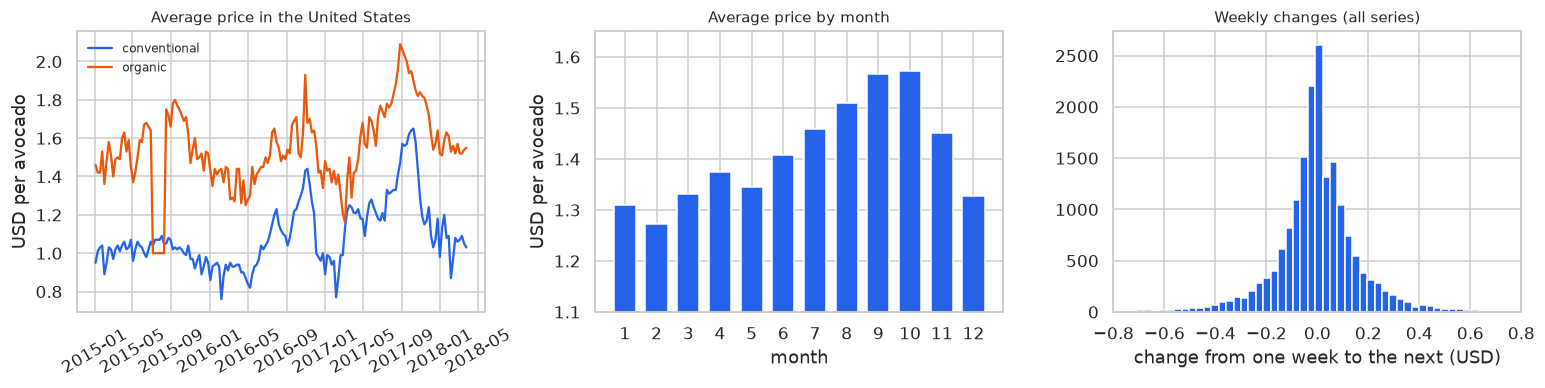

Mean price by type: {'conventional': 1.16, 'organic': 1.65}
Weeks with the national organic at exactly 1.00 USD: 6 | from 2015-07-05 to 2015-08-09
Mean price by month: {1: 1.31, 2: 1.27, 3: 1.33, 4: 1.37, 5: 1.35, 6: 1.41, 7: 1.46, 8: 1.51, 9: 1.57, 10: 1.57, 11: 1.45, 12: 1.33}
Weekly change: mean 0.0003 | std 0.17 | half of the changes are smaller than 0.07 USD
Correlation between one week's change and the previous one: -0.3


In [4]:
national = {t: series[('TotalUS', t)] for t in ['conventional', 'organic']}
changes = pd.concat([s.diff() for s in series.values()]).dropna()
previous = pd.DataFrame({'change': pd.concat([s.diff() for s in series.values()]).values,
                         'prior': pd.concat([s.diff().shift(1) for s in series.values()]).values}).dropna()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(national['conventional'], color=BLUE, label='conventional'); ax[0].plot(national['organic'], color=ORANGE, label='organic')
ax[0].set_ylabel('USD per avocado'); ax[0].set_title('Average price in the United States'); ax[0].legend(fontsize=8); ax[0].tick_params(axis='x', rotation=30)
by_month = prices.groupby(prices.Date.dt.month).AveragePrice.mean()
ax[1].bar(by_month.index, by_month.values, color=BLUE, width=0.7); ax[1].set_ylim(1.1, 1.65)
ax[1].set_xlabel('month'); ax[1].set_ylabel('USD per avocado'); ax[1].set_title('Average price by month'); ax[1].set_xticks(range(1, 13))
ax[2].hist(changes, bins=80, color=BLUE); ax[2].set_xlim(-0.8, 0.8)
ax[2].set_xlabel('change from one week to the next (USD)'); ax[2].set_title('Weekly changes (all series)')
plt.tight_layout(); plt.show()

print('Mean price by type:', prices.groupby('type').AveragePrice.mean().round(2).to_dict())
fixed = national['organic'][national['organic'] == 1.0]
print('Weeks with the national organic at exactly 1.00 USD:', len(fixed), '| from', fixed.index.min().date(), 'to', fixed.index.max().date())
print('Mean price by month:', by_month.round(2).to_dict())
print('Weekly change: mean', round(changes.mean(), 4), '| std', round(changes.std(), 3), '| half of the changes are smaller than', round(changes.abs().median(), 2), 'USD')
print('Correlation between one week\'s change and the previous one:', round(previous.change.corr(previous.prior), 2))

**Findings**
- There are no nulls or duplicates. Of the 108 series, 107 have their 169 consecutive weeks; one (`WestTexNewMexico`, organic) has missing weeks and **is excluded**, because the features are computed with consecutive weeks.
- **Organic costs more** (1.65 USD on average versus 1.16) and the two types move together. In 2017 there was a strong rise until September and a fast drop afterwards.
- There is one odd data point: the national organic shows up 6 consecutive weeks of 2015 at exactly 1.00 USD. It is left as it is; it affects a single series.
- **Seasonality:** the price rises over the year until September and October (1.57 USD) and drops from December to February (1.27 to 1.33).
- **Weekly changes are small** (half are below 7 cents) **and tend to reverse**: the correlation between one week's change and the previous one is −0.30. If the price went up this week, the most likely thing is that it drops a bit the next. That is the signal a model can exploit and that the naive baseline ignores.

## 4. Model (2 pts)

**Preprocessing:** the seven variables come from `build_features` (the same function the API uses). Ridge includes standardization inside a `Pipeline`; trees do not need it.

**Temporal split (no shuffling):**
- *Training:* up to June 2017.
- *Validation:* July to December 2017, to choose the model.
- *Test:* January to March 2018, used once at the end.

**Algorithms compared:** two baselines (*naive* = no change, and *mean of the last 4 weeks*) and three models, tuned with `GridSearchCV` over four temporal folds (each fold trains with weeks earlier than the ones it evaluates):
- **Ridge** (Hoerl and Kennard, 1970): linear regression with penalty.
- **Random Forest** (Breiman, 2001).
- **Histogram Gradient Boosting** (Friedman, 2001).

In [5]:
# One row per series and week: that week's features and, as the target, the change of the following week
parts = []
for (region, kind), s in series.items():
    f = build_features(s)
    f['target'] = s.shift(-1) - s                      # price change of the following week
    f['next_price'] = s.shift(-1)
    f['target_date'] = s.index + pd.Timedelta(days=7)
    f['region'], f['type'] = region, kind
    parts.append(f)
panel = pd.concat(parts).dropna().sort_values('target_date').reset_index(drop=True)

trn = panel[panel.target_date < '2017-07-01'].reset_index(drop=True)
val = panel[(panel.target_date >= '2017-07-01') & (panel.target_date < '2018-01-01')]
tst = panel[panel.target_date >= '2018-01-01']
for name, part in [('training', trn), ('validation', val), ('test', tst)]:
    print(f'{name:11s} {len(part):6d} rows | {part.target_date.min().date()} to {part.target_date.max().date()} ({part.target_date.nunique()} weeks)')

# Temporal folds to tune hyperparameters: always trained with weeks earlier than the ones evaluated
dates = np.sort(trn.target_date.unique())
folds = [(np.where(trn.target_date.isin(dates[i]))[0], np.where(trn.target_date.isin(dates[j]))[0])
         for i, j in TimeSeriesSplit(n_splits=4).split(dates)]
naive_rmse_cv = [float(np.sqrt((trn.target.iloc[j] ** 2).mean())) for _, j in folds]
print('RMSE of the naive baseline in each fold:', np.round(naive_rmse_cv, 4), '| mean', round(np.mean(naive_rmse_cv), 4))

training     12626 rows | 2015-03-29 to 2017-06-25 (118 weeks)
validation    2889 rows | 2017-07-02 to 2017-12-31 (27 weeks)
test          1284 rows | 2018-01-07 to 2018-03-25 (12 weeks)
RMSE of the naive baseline in each fold: [0.1601 0.1559 0.1992 0.2078] | mean 0.1808


In [6]:
grids = {
    'Ridge':             (Pipeline([('scale', StandardScaler()), ('model', Ridge())]), {'model__alpha': [10, 100, 1000, 3000]}),
    'Random Forest':     (Pipeline([('model', RandomForestRegressor(200, random_state=SEED, n_jobs=-1))]),
                          {'model__min_samples_leaf': [20, 50], 'model__max_features': [0.33, 0.6]}),
    'Gradient Boosting': (Pipeline([('model', HistGradientBoostingRegressor(random_state=SEED))]),
                          {'model__learning_rate': [0.03, 0.1], 'model__max_depth': [2, 3], 'model__max_iter': [100, 200]}),
}
best = {}
for name, (p, grid) in grids.items():
    gs = GridSearchCV(p, grid, cv=folds, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(trn[FEATURES], trn.target)
    best[name] = gs
    per_fold = [float(-gs.cv_results_[f'split{k}_test_score'][gs.best_index_]) for k in range(len(folds))]
    print(f'{name:18s} CV RMSE: {-gs.best_score_:.4f} | per fold {np.round(per_fold, 4)} | best parameters: {gs.best_params_}')

Ridge              CV RMSE: 0.1656 | per fold [0.1422 0.1401 0.1847 0.1953] | best parameters: {'model__alpha': 1000}


Random Forest      CV RMSE: 0.1674 | per fold [0.1435 0.1413 0.191  0.1939] | best parameters: {'model__max_features': 0.33, 'model__min_samples_leaf': 20}


Gradient Boosting  CV RMSE: 0.1674 | per fold [0.1451 0.1415 0.1893 0.1938] | best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__max_iter': 100}


## 5. Evaluation (1 pt)
The predicted price is rebuilt (`this week's price + predicted change`) and the error is measured in dollars. *R² of the change* indicates what part of the weekly variation the model explains: 0 means it explains nothing.

In [7]:
def evaluate(predicted_change, part):
    pred = part.price + predicted_change
    return {'RMSE (USD)': np.sqrt(mean_squared_error(part.next_price, pred)),
            'MAE (USD)': mean_absolute_error(part.next_price, pred),
            'Change R²': r2_score(part.target, predicted_change)}

predictors = {'Naive baseline (same as this week)': lambda part: np.zeros(len(part)),
              '4-week mean baseline':                lambda part: -part.dist_mean_4.values,
              **{n: (lambda part, gs=gs: gs.predict(part[FEATURES])) for n, gs in best.items()}}
val_table  = pd.DataFrame({n: evaluate(f(val), val) for n, f in predictors.items()}).T.round(4)
test_table = pd.DataFrame({n: evaluate(f(tst), tst) for n, f in predictors.items()}).T.round(4)
print('VALIDATION (July to December 2017)'); display(val_table)
print('TEST (January to March 2018)'); display(test_table)

chosen = min(best, key=lambda n: val_table.loc[n, 'RMSE (USD)'])
print('Selected model (lowest validation RMSE among the ML models):', chosen)

VALIDATION (July to December 2017)


,RMSE (USD),MAE (USD),Change R²
Naive baseline (same as this week),0.1626,0.1082,-0.0040
4-week mean baseline,0.1959,0.1427,-0.4577
Ridge,0.1648,0.1172,-0.0315
Random Forest,0.1640,0.1160,-0.0216
Gradient Boosting,0.1624,0.1144,-0.0026


TEST (January to March 2018)


,RMSE (USD),MAE (USD),Change R²
Naive baseline (same as this week),0.1752,0.1193,-0.0009
4-week mean baseline,0.1519,0.1100,0.2472
Ridge,0.1478,0.1039,0.2879
Random Forest,0.1413,0.0998,0.3484
Gradient Boosting,0.1487,0.1038,0.2791


Selected model (lowest validation RMSE among the ML models): Gradient Boosting


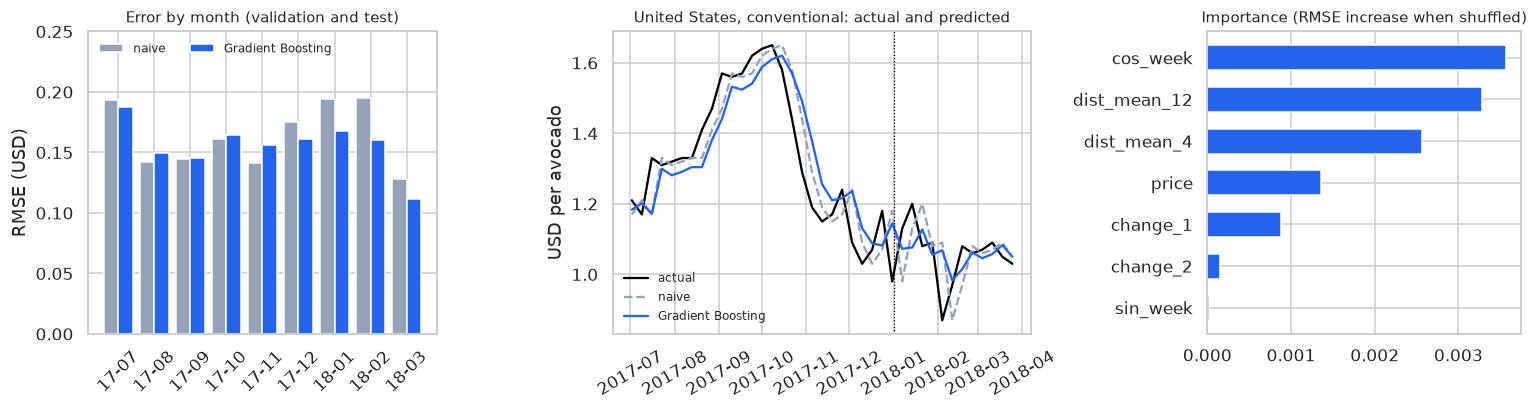

             naive  model  improvement %
target_date                             
2017-07      0.193  0.188          2.789
2017-08      0.142  0.150         -5.270
2017-09      0.144  0.145         -0.613
2017-10      0.161  0.164         -2.035
2017-11      0.141  0.157        -10.687
2017-12      0.175  0.161          8.128
2018-01      0.194  0.168         13.549
2018-02      0.195  0.160         17.765
2018-03      0.128  0.112         12.840

Importance: {'cos_week': 0.0036, 'dist_mean_12': 0.0033, 'dist_mean_4': 0.0026, 'price': 0.0014, 'change_1': 0.0009, 'change_2': 0.0002, 'sin_week': 0.0}
RMSE improvement over the naive baseline | training folds: [9.4 9.2 5.  6.7] % | validation: 0.1 % | test: 15.1 %
conventional  naive RMSE 0.1590 | model 0.1475
organic       naive RMSE 0.1739 | model 0.1686


In [8]:
final = best[chosen].best_estimator_
out_of_sample = pd.concat([val, tst]).assign(pred=lambda d: d.price + final.predict(d[FEATURES]))

# Month-by-month error, against the naive baseline
by_month = out_of_sample.groupby(out_of_sample.target_date.dt.to_period('M')).apply(lambda d: pd.Series({
    'naive': np.sqrt(((d.next_price - d.price) ** 2).mean()),
    'model': np.sqrt(((d.next_price - d.pred) ** 2).mean())}))
by_month['improvement %'] = (1 - by_month.model / by_month.naive) * 100

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={'width_ratios': [1, 1.2, 0.9]})
x = np.arange(len(by_month))
ax[0].bar(x - 0.2, by_month.naive, 0.4, color=GRAY, label='naive'); ax[0].bar(x + 0.2, by_month.model, 0.4, color=BLUE, label=chosen)
ax[0].set_xticks(x); ax[0].set_xticklabels([str(m)[2:] for m in by_month.index], rotation=45); ax[0].set_ylabel('RMSE (USD)')
ax[0].set_title('Error by month (validation and test)'); ax[0].set_ylim(0, 0.25); ax[0].legend(fontsize=8, loc='upper left', ncol=2)

example = out_of_sample[(out_of_sample.region == 'TotalUS') & (out_of_sample.type == 'conventional')].set_index('target_date')
ax[1].plot(example.next_price, color='black', label='actual'); ax[1].plot(example.price, color=GRAY, ls='--', label='naive')
ax[1].plot(example.pred, color=BLUE, label=chosen); ax[1].axvline(pd.Timestamp('2018-01-01'), color='black', lw=0.8, ls=':')
ax[1].set_ylabel('USD per avocado'); ax[1].set_title('United States, conventional: actual and predicted'); ax[1].legend(fontsize=8); ax[1].tick_params(axis='x', rotation=30)

imp = permutation_importance(final, out_of_sample[FEATURES], out_of_sample.target, scoring='neg_root_mean_squared_error', n_repeats=5, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
ax[2].barh(importance.index, importance.values, color=BLUE, height=0.6); ax[2].set_title('Importance (RMSE increase when shuffled)')
plt.tight_layout(); plt.show()

print(by_month.round(3).to_string())
print('\nImportance:', importance.sort_values(ascending=False).round(4).to_dict())
cv_gain = 1 - np.array([-best[chosen].cv_results_[f'split{k}_test_score'][best[chosen].best_index_] for k in range(len(folds))]) / np.array(naive_rmse_cv)
print('RMSE improvement over the naive baseline | training folds:', np.round(cv_gain * 100, 1), '%',
      '| validation:', round((1 - val_table.loc[chosen, 'RMSE (USD)'] / val_table.iloc[0, 0]) * 100, 1), '%',
      '| test:', round((1 - test_table.loc[chosen, 'RMSE (USD)'] / test_table.iloc[0, 0]) * 100, 1), '%')
for kind in ['conventional', 'organic']:
    d = out_of_sample[out_of_sample.type == kind]
    print(f'{kind:13s} naive RMSE {np.sqrt(((d.next_price - d.price) ** 2).mean()):.4f} | model {np.sqrt(((d.next_price - d.pred) ** 2).mean()):.4f}')

**Reading the results**
- **In training the three models beat the naive baseline** in the four temporal folds: the Gradient Boosting RMSE is 5% to 10% lower (on average, 0.167 versus 0.181).
- **On validation (July to December 2017) it ties with the naive baseline:** 0.162 versus 0.163. It is the period of the strong rise and fall of prices; when the price goes in a single direction, betting that the change will reverse does not help, and between August and November the model is even a bit worse.
- **On test (January to March 2018) it wins clearly again:** RMSE of 0.149 versus 0.175, a **15% reduction**, and it explains 28% of the weekly variation.
- **Choice:** Gradient Boosting, for having the lowest validation RMSE. The three models are within 4 thousandths of each other in validation; on test the Random Forest was the best (0.141).
- **What the model uses:** the time of year and how far the price is from its mean of the last three months and of the last month. That is, seasonality and mean reversion.
- **It improves more on conventional** (RMSE from 0.159 to 0.145 out of sample) than on organic (0.174 to 0.168).

## 6. Conclusion (0.5 pt)

**How well does it work?** It predicts next week's price with a mean error of about **10 cents** (MAE of 0.10 USD on test, for an avocado that costs around 1.40). It beats the naive baseline in most periods, but not in all: it improves between 5% and 15% when the market is stable and ties when there is a sustained rise or fall.

**What was learned**
- Unlike bitcoin and stocks, here **there is something predictable**: weekly changes tend to reverse and there is seasonality. It is a modest signal, but a real one.
- The naive baseline is a serious rival: without comparing with it, an error of 10 cents would look excellent, when on test the naive one already gets 12.
- Evaluating over several periods avoided a wrong conclusion: with only the validation one would say the model is useless, and with only the test, that it always improves 15%.

**Limitations**
- The data ends in March 2018, so "next week" is the week of April 1, 2018, unless more recent prices are given.
- They are United States prices; they do not describe other markets.
- Three years are few to learn the seasonality well: there are only three yearly cycles.

**Possible improvements:** more years of history and a separate model for each avocado type.

## Export the model
The chosen model is **retrained with all the data** and saved together with the last 16 weeks of prices of each region and type, so the API can predict "next week" without receiving data.

In [9]:
final_model = clone(final).fit(panel[FEATURES], panel.target)

bundle = {
    'pipeline': final_model, 'model': chosen, 'features': FEATURES, 'sklearn': sklearn.__version__,
    'history': {f'{region}|{kind}': {'dates': [d.date().isoformat() for d in s.index[-16:]], 'prices': s.iloc[-16:].round(2).tolist()}
                for (region, kind), s in series.items()},
    'regions': sorted({region for region, _ in series}),
    'last_date': prices.Date.max().date().isoformat(),
    'validation_metrics': val_table.loc[chosen].to_dict(), 'test_metrics': test_table.loc[chosen].to_dict(),
}
joblib.dump(bundle, '../models/avocado.joblib', compress=3)
print('Saved ../models/avocado.joblib | last data point:', bundle['last_date'], '| series with history:', len(bundle['history']))

# API contract check
from predictors.avocado import predict
print(predict({'region': 'Boston', 'type': 'organic'}))
predict({})

Saved ../models/avocado.joblib | last data point: 2018-03-25 | series with history: 107
{'prediction': 1.77, 'unit': 'USD per avocado', 'current_price': 1.74, 'change_pct': 1.7, 'region': 'Boston', 'type': 'organic', 'base_date': '2018-03-25', 'prediction_date': '2018-04-01', 'model': 'Gradient Boosting', 'note': 'Weekly average price in the United States (Hass Avocado Board). Academic reference.'}


{'prediction': 1.05,
 'unit': 'USD per avocado',
 'current_price': 1.03,
 'change_pct': 1.8,
 'region': 'TotalUS',
 'type': 'conventional',
 'base_date': '2018-03-25',
 'prediction_date': '2018-04-01',
 'model': 'Gradient Boosting',
 'note': 'Weekly average price in the United States (Hass Avocado Board). Academic reference.'}